## Plot data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
plt.style.use("ggplot")

In [2]:
df = pd.read_csv("D:/KLTN/Week 1/VND=X.csv", index_col="Date", parse_dates=True)

In [3]:
df

,Close,High,Low,Open,Volume,Mid,Range
Date,,,,,,,
2020-01-01,23171.0,23171.0,23171.000000,23171.000000,0,23171.000000,0.000000
2020-01-02,23171.0,23171.0,22805.605469,22835.800781,0,22988.302734,365.394531
2020-01-03,23171.0,23171.0,22812.912109,23171.000000,0,22991.956055,358.087891
2020-01-06,23171.0,23171.0,22744.150391,22744.150391,0,22957.575195,426.849609
2020-01-07,23171.0,23171.0,22822.310547,23171.000000,0,22996.655273,348.689453
...,...,...,...,...,...,...,...
2026-08-24,26110.0,26187.0,26050.000000,26120.000000,0,26118.500000,137.000000
2026-08-25,26172.0,26177.0,26096.000000,26172.000000,0,26136.500000,81.000000
2026-08-26,26109.0,26114.0,26070.000000,26109.000000,0,26092.000000,44.000000


In [4]:
len_df = len(df)
train_end = int(len_df * 0.7)
val_end = int(len_df * 0.85)

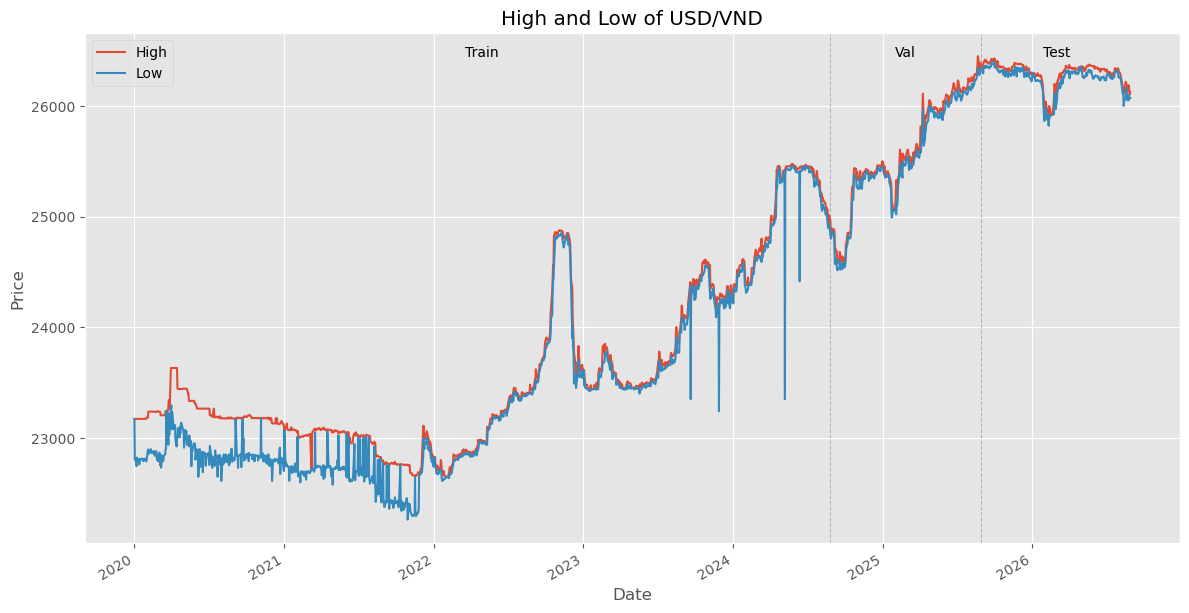

In [5]:
df.index = pd.to_datetime(df.index)


ax = df[["High", "Low"]].plot(figsize=(12,6))

date_split_1 = df.index[train_end]
date_split_2 = df.index[val_end]

ax.axvline(x=date_split_1, color='gray', linestyle='--', alpha=0.5, linewidth=0.75)
ax.axvline(x=date_split_2, color='gray', linestyle='--', alpha=0.5, linewidth=0.75)

y_pos = df['High'].max() 
ax.text(df.index[train_end // 2], y_pos, 'Train', ha='center', fontsize=10)
ax.text(df.index[(train_end + val_end) // 2], y_pos, 'Val', ha='center', fontsize=10)
ax.text(df.index[(val_end + len_df) // 2], y_pos, 'Test', ha='center', fontsize=10)

ax.set_xlabel('Date')
ax.set_ylabel('Price')
ax.legend(loc='upper left')
plt.tight_layout()
plt.title("High and Low of USD/VND")
plt.show()

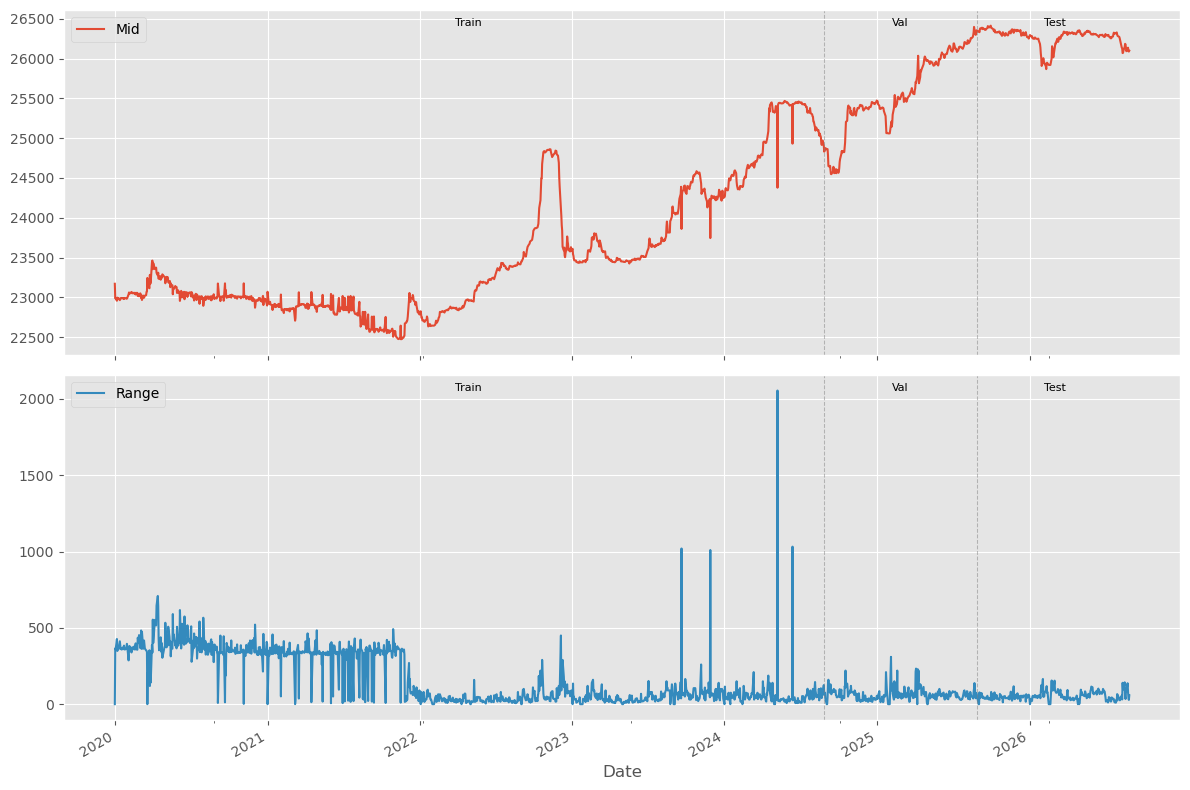

In [6]:
import matplotlib.pyplot as plt

# Khởi tạo khung vẽ 2 dòng, 1 cột
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(12, 8), sharex=True)


date_split_1 = df.index[train_end]
date_split_2 = df.index[val_end]
len_df = len(df) 

# ==========================================
# 1. PLot Mid Features (ĐỒ THỊ TRÊN - ax1)
# ==========================================

df["Mid"].plot(ax=ax1, label='Mid', color='#e24a33')

ax1.axvline(x=date_split_1, color='gray', linestyle='--', alpha=0.5, linewidth=0.75)
ax1.axvline(x=date_split_2, color='gray', linestyle='--', alpha=0.5, linewidth=0.75)


y_pos_mid = df['Mid'].max()
ax1.text(df.index[train_end // 2], y_pos_mid, 'Train', ha='center', fontsize=8)
ax1.text(df.index[(train_end + val_end) // 2], y_pos_mid, 'Val', ha='center', fontsize=8)
ax1.text(df.index[(val_end + len_df) // 2], y_pos_mid, 'Test', ha='center', fontsize=8)

ax1.legend(loc='upper left')

# ==========================================
# 2. PLot Range Feature (ĐỒ THỊ DƯỚI - ax2)
# ==========================================

df["Range"].plot(ax=ax2, label='Range', color='#348abd')

ax2.axvline(x=date_split_1, color='gray', linestyle='--', alpha=0.5, linewidth=0.75)
ax2.axvline(x=date_split_2, color='gray', linestyle='--', alpha=0.5, linewidth=0.75)


y_pos_range = df['Range'].max() 
ax2.text(df.index[train_end // 2], y_pos_range, 'Train', ha='center', fontsize=8)
ax2.text(df.index[(train_end + val_end) // 2], y_pos_range, 'Val', ha='center', fontsize=8)
ax2.text(df.index[(val_end + len_df) // 2], y_pos_range, 'Test', ha='center', fontsize=8)

ax2.set_xlabel('Date')
ax2.legend(loc='upper left')


plt.tight_layout()
plt.show()

## Thêm hình sau khi scale (train, val, test)


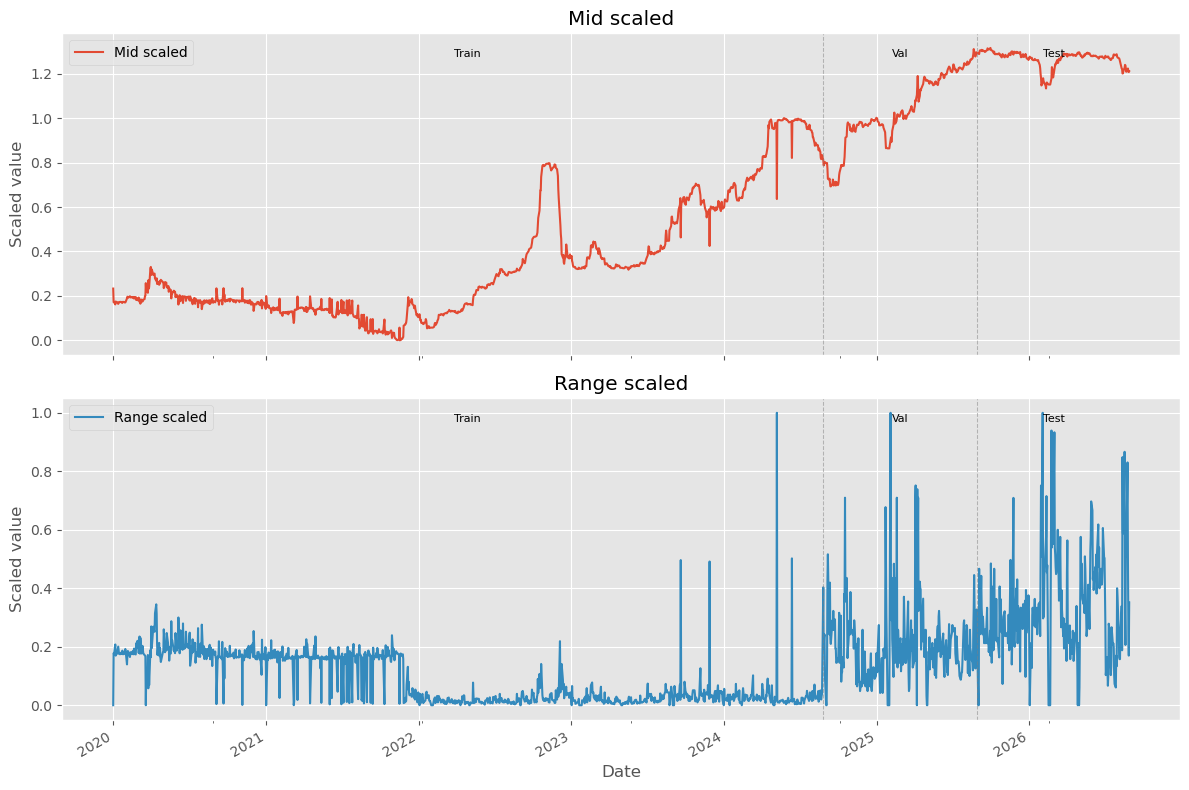

In [8]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

base_dir = Path(r"D:\KLTN\Week 1")


def load_scaled_series(filename, column):
    data = pd.read_csv(base_dir / filename, parse_dates=["Date"])
    return data.set_index("Date")[column]


# Đọc dữ liệu Mid đã scaled
mid_train = load_scaled_series("Midpoint_train_scaled.csv", "Mid")
mid_val = load_scaled_series("Midpoint_val_scaled.csv", "Mid")
mid_test = load_scaled_series("Midpoint_test_scaled.csv", "Mid")
mid_scaled = pd.concat([mid_train, mid_val, mid_test])

# Đọc dữ liệu Range đã scaled
range_train = load_scaled_series("Range_train_scaled.csv", "Range")
range_val = load_scaled_series("Range_val_scaled.csv", "Range")
range_test = load_scaled_series("Range_test_scaled.csv", "Range")
range_scaled = pd.concat([range_train, range_val, range_test])

# Vị trí bắt đầu của tập Val và Test
date_split_1 = mid_val.index[0]
date_split_2 = mid_test.index[0]

n_train = len(mid_train)
n_val = len(mid_val)

fig, (ax1, ax2) = plt.subplots(
    nrows=2, ncols=1, figsize=(12, 8), sharex=True
)

# Mid scaled
mid_scaled.plot(ax=ax1, label="Mid scaled", color="#e24a33")
ax1.axvline(date_split_1, color="gray", linestyle="--", alpha=0.5, linewidth=0.75)
ax1.axvline(date_split_2, color="gray", linestyle="--", alpha=0.5, linewidth=0.75)

ax1.text(mid_scaled.index[n_train // 2], 0.95, "Train",
         transform=ax1.get_xaxis_transform(), ha="center", va="top", fontsize=8)
ax1.text(mid_scaled.index[n_train + n_val // 2], 0.95, "Val",
         transform=ax1.get_xaxis_transform(), ha="center", va="top", fontsize=8)
ax1.text(mid_scaled.index[n_train + n_val + len(mid_test) // 2], 0.95, "Test",
         transform=ax1.get_xaxis_transform(), ha="center", va="top", fontsize=8)

ax1.set_title("Mid scaled")
ax1.set_ylabel("Scaled value")
ax1.legend(loc="upper left")

# Range scaled
range_scaled.plot(ax=ax2, label="Range scaled", color="#348abd")
ax2.axvline(date_split_1, color="gray", linestyle="--", alpha=0.5, linewidth=0.75)
ax2.axvline(date_split_2, color="gray", linestyle="--", alpha=0.5, linewidth=0.75)

ax2.text(range_scaled.index[n_train // 2], 0.95, "Train",
         transform=ax2.get_xaxis_transform(), ha="center", va="top", fontsize=8)
ax2.text(range_scaled.index[n_train + n_val // 2], 0.95, "Val",
         transform=ax2.get_xaxis_transform(), ha="center", va="top", fontsize=8)
ax2.text(range_scaled.index[n_train + n_val + len(range_test) // 2], 0.95, "Test",
         transform=ax2.get_xaxis_transform(), ha="center", va="top", fontsize=8)

ax2.set_title("Range scaled")
ax2.set_xlabel("Date")
ax2.set_ylabel("Scaled value")
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()